# Assessment-Lab-5 - 10.10.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    Generate the model to classify the income of the persons using Random
    Forest classifier and Ada Boost classifier for the given dataset “adult”.
    Use the following input features - 'age', 'education.num',
    'marital.status', 'capital.gain', 'capital.loss', 'hours.per.week' and
    target feature as “income”. Use 70:30 split and analyze the performance
    of the data and visualize the results.

### Random Forest & AdaBoost - Income classification

#### Load dataset

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [24]:
adult_df = pd.read_csv('Assessment Lab 5- 10.10.26/adult.csv')
adult_df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [25]:
adult_df['income'].value_counts()

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

#### Select features & target

In [26]:
features_adult = ['age', 'education.num', 'marital.status', 'capital.gain',
                   'capital.loss', 'hours.per.week']

X_adult = adult_df[features_adult].copy()
y_adult = (adult_df['income'] == '>50K').astype(int)

#### Train-test split

In [27]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_adult, y_adult, test_size=0.3, random_state=1265, stratify=y_adult
)

#### Encode categorical feature (fit on training data only)

In [28]:
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train[['marital.status']] = encoder.fit_transform(X_train_raw[['marital.status']])
X_test[['marital.status']] = encoder.transform(X_test_raw[['marital.status']])

#### Train models

In [29]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=1265)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

ada_model = AdaBoostClassifier(n_estimators=200, algorithm='SAMME', random_state=1265)
ada_model.fit(X_train, y_train)
y_pred_ada = ada_model.predict(X_test)

#### Performance evaluation

In [30]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
ada_accuracy = accuracy_score(y_test, y_pred_ada)
ada_f1 = f1_score(y_test, y_pred_ada)

print(f"Random Forest - Accuracy: {rf_accuracy:.4f}, F1 Score: {rf_f1:.4f}")
print(f"AdaBoost - Accuracy: {ada_accuracy:.4f}, F1 Score: {ada_f1:.4f}")
print()
print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))
print("AdaBoost Classification Report:")
print(classification_report(y_test, y_pred_ada))

Random Forest - Accuracy: 0.8440, F1 Score: 0.6506
AdaBoost - Accuracy: 0.8589, F1 Score: 0.6713

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90      7417
           1       0.71      0.60      0.65      2352

    accuracy                           0.84      9769
   macro avg       0.79      0.76      0.78      9769
weighted avg       0.84      0.84      0.84      9769

AdaBoost Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      7417
           1       0.76      0.60      0.67      2352

    accuracy                           0.86      9769
   macro avg       0.82      0.77      0.79      9769
weighted avg       0.85      0.86      0.85      9769



#### Visualize results

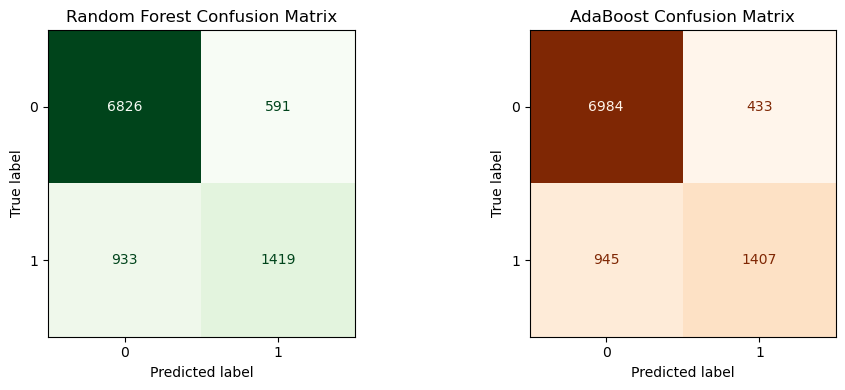

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_rf = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(confusion_matrix=cm_rf).plot(ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Random Forest Confusion Matrix')

cm_ada = confusion_matrix(y_test, y_pred_ada)
ConfusionMatrixDisplay(confusion_matrix=cm_ada).plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title('AdaBoost Confusion Matrix')

plt.tight_layout()
plt.show()

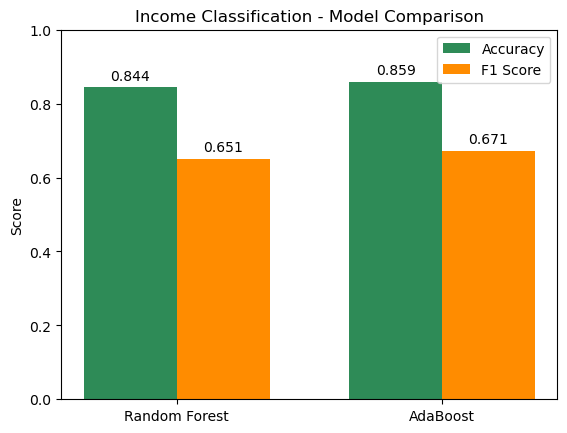

In [32]:
x_pos = np.arange(2)
width = 0.35

plt.bar(x_pos - width/2, [rf_accuracy, ada_accuracy], width, label='Accuracy', color='seagreen')
plt.bar(x_pos + width/2, [rf_f1, ada_f1], width, label='F1 Score', color='darkorange')
plt.xticks(x_pos, ['Random Forest', 'AdaBoost'])
plt.ylabel('Score')
plt.ylim(0, 1)
plt.title('Income Classification - Model Comparison')
plt.legend()
for i, (acc, f1) in enumerate(zip([rf_accuracy, ada_accuracy], [rf_f1, ada_f1])):
    plt.text(i - width/2, acc + 0.02, f"{acc:.3f}", ha='center')
    plt.text(i + width/2, f1 + 0.02, f"{f1:.3f}", ha='center')
plt.show()

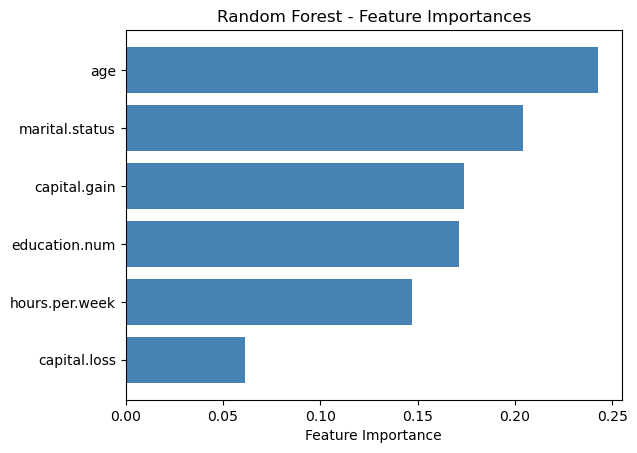

In [33]:
rf_importances = pd.Series(rf_model.feature_importances_, index=features_adult).sort_values()

plt.barh(rf_importances.index, rf_importances.values, color='steelblue')
plt.xlabel('Feature Importance')
plt.title('Random Forest - Feature Importances')
plt.show()